In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

# Path to one training image in Part B
image_path = "data/part_B/train_data/images/IMG_1.jpg"

# Path to its matching ground-truth annotation file
mat_path = "data/part_B/train_data/ground-truth/GT_IMG_1.mat"

# Check both files actually exist before trying to open them
print("Image exists:", os.path.exists(image_path))
print("Annotation exists:", os.path.exists(mat_path))

Image exists: True
Annotation exists: True


In [3]:
from scipy.io import loadmat

mat = loadmat(mat_path)
print("Top-level keys:", mat.keys())
print(mat['image_info'])

Top-level keys: dict_keys(['__header__', '__version__', '__globals__', 'image_info'])
[[array([[(array([[  32.67954877,  753.52165403],
                 [ 184.60695349,  690.79933098],
                 [ 344.89733461,  577.8991495 ],
                 [ 328.1713818 ,  536.08426746],
                 [ 329.5652112 ,  473.36194441],
                 [ 643.17682645,  533.29660866],
                 [ 661.29660866,  681.04252518],
                 [ 803.46720757,  580.6868083 ],
                 [ 814.61784278,  502.63236184],
                 [ 757.47083734,  392.51983915],
                 [ 770.01530195,  364.64325113],
                 [ 799.28571937,  315.85922209],
                 [ 728.20041991,  328.4036867 ],
                 [ 899.64143625,  405.06430376],
                 [ 919.15504786,  529.11512046],
                 [ 924.73036547,  278.22582826],
                 [ 965.1514181 ,  250.34924024],
                 [1018.11693534,  236.41094623],
                 [ 938.66865948

Number of head points: 233
Ground truth count: 233


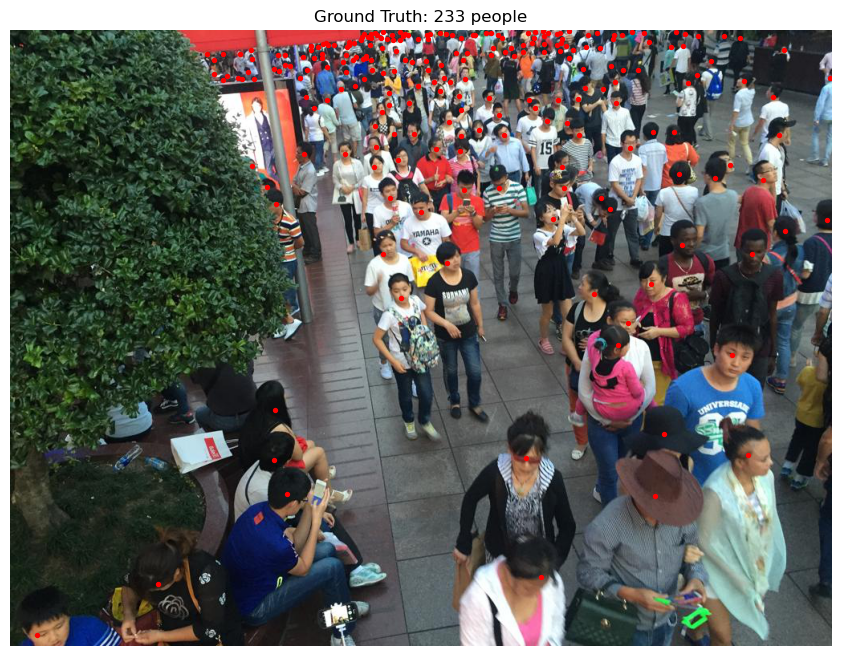

In [4]:
import matplotlib.pyplot as plt

# Load the image
img = plt.imread(image_path)

# Extract head points from the .mat structure
points = mat['image_info'][0][0][0][0][0]
count = mat['image_info'][0][0][0][0][1][0][0]

print("Number of head points:", len(points))
print("Ground truth count:", count)

# Plot image with red dots on each head
plt.figure(figsize=(12, 8))
plt.imshow(img)
plt.scatter(points[:, 0], points[:, 1], c='red', s=8)
plt.title(f"Ground Truth: {int(count)} people")
plt.axis('off')
plt.show()

Sum of density map (should ≈ head count): 233.00008
Ground truth count: 233


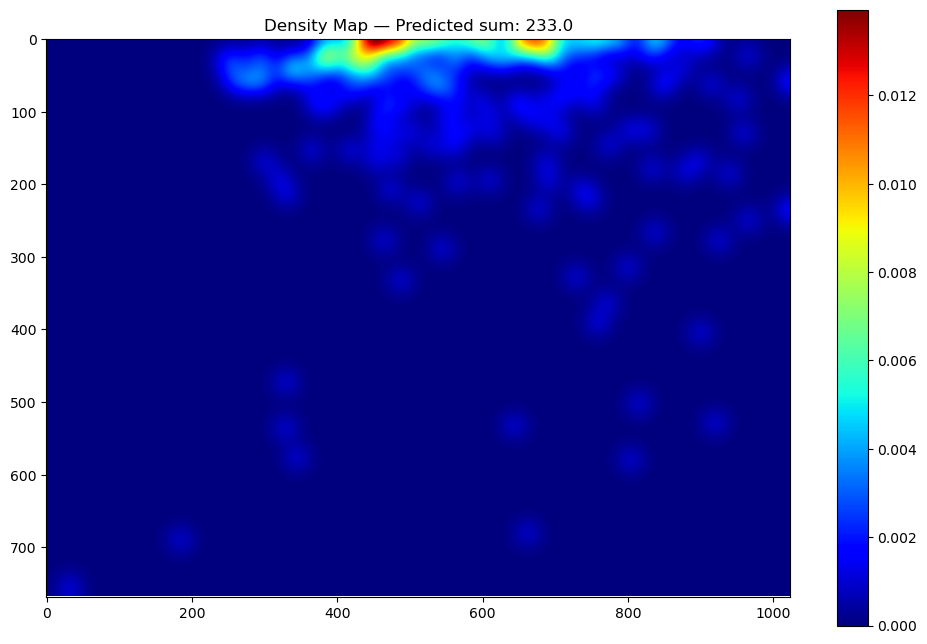

In [5]:
import numpy as np
from scipy.ndimage import gaussian_filter

def generate_density_map(img_shape, points, sigma=15):
    """
    img_shape: (height, width) of the image
    points: array of (x, y) head coordinates
    sigma: spread of the Gaussian blob (bigger = more blur)
    """
    density_map = np.zeros(img_shape, dtype=np.float32)
    h, w = img_shape

    for x, y in points:
        x, y = int(x), int(y)
        if 0 <= y < h and 0 <= x < w:
            density_map[y, x] += 1  # place a "delta" at the head location

    # Blur all the point-deltas into smooth Gaussian blobs
    density_map = gaussian_filter(density_map, sigma=sigma)
    return density_map

# Generate the density map for our test image
h, w = img.shape[0], img.shape[1]
density_map = generate_density_map((h, w), points, sigma=15)

print("Sum of density map (should ≈ head count):", density_map.sum())
print("Ground truth count:", count)

# Visualize
plt.figure(figsize=(12, 8))
plt.imshow(density_map, cmap='jet')
plt.title(f"Density Map — Predicted sum: {density_map.sum():.1f}")
plt.colorbar()
plt.show()

In [6]:
import os

for split in ["train_data", "test_data"]:
    img_dir = f"data/part_B/{split}/images"
    gt_dir = f"data/part_B/{split}/ground-truth"
    print(split, "->", os.path.exists(img_dir), os.path.exists(gt_dir))
    if os.path.exists(img_dir):
        print("  num images:", len(os.listdir(img_dir)))
    if os.path.exists(gt_dir):
        print("  num gt files:", len(os.listdir(gt_dir)))

train_data -> True True
  num images: 400
  num gt files: 400
test_data -> True True
  num images: 316
  num gt files: 316


In [1]:
import os
import numpy as np
import cv2
from scipy.io import loadmat
from scipy.ndimage import gaussian_filter

def load_points(mat_path):
    mat = loadmat(mat_path)
    return mat["image_info"][0][0][0][0][0]

def make_density(shape, points, sigma=15):
    h, w = shape
    d = np.zeros((h, w), dtype=np.float32)
    for x, y in points:
        x, y = int(x), int(y)
        if 0 <= x < w and 0 <= y < h:
            d[y, x] += 1
    return gaussian_filter(d, sigma=sigma)

def downsample_sum(d, factor=8):
    h, w = d.shape
    h8, w8 = h // factor, w // factor
    d = d[:h8 * factor, :w8 * factor]
    return d.reshape(h8, factor, w8, factor).sum(axis=(1, 3))

root = "data/part_B"
for split in ["train_data", "test_data"]:
    img_dir = f"{root}/{split}/images"
    gt_dir = f"{root}/{split}/ground-truth"
    out_dir = f"{root}/{split}/density8"
    os.makedirs(out_dir, exist_ok=True)

    names = sorted(os.listdir(img_dir))
    for i, name in enumerate(names):
        img = cv2.imread(f"{img_dir}/{name}")
        h, w = img.shape[:2]
        pts = load_points(f"{gt_dir}/GT_{name.replace('.jpg', '.mat')}")
        d = downsample_sum(make_density((h, w), pts), 8)
        np.save(f"{out_dir}/{name.replace('.jpg', '.npy')}", d)
        if i % 50 == 0:
            print(split, i, "/", len(names), "| people:", len(pts), "| map sum:", round(float(d.sum()), 2))
print("Done!")

train_data 0 / 400 | people: 233 | map sum: 233.0
train_data 50 / 400 | people: 26 | map sum: 26.0
train_data 100 / 400 | people: 43 | map sum: 43.0
train_data 150 / 400 | people: 54 | map sum: 54.0
train_data 200 / 400 | people: 96 | map sum: 96.0
train_data 250 / 400 | people: 178 | map sum: 178.0
train_data 300 / 400 | people: 115 | map sum: 115.0
train_data 350 / 400 | people: 138 | map sum: 138.0
test_data 0 / 316 | people: 23 | map sum: 23.0
test_data 50 / 316 | people: 59 | map sum: 59.0
test_data 100 / 316 | people: 277 | map sum: 277.0
test_data 150 / 316 | people: 212 | map sum: 212.0
test_data 200 / 316 | people: 61 | map sum: 61.0
test_data 250 / 316 | people: 95 | map sum: 95.0
test_data 300 / 316 | people: 59 | map sum: 59.0
Done!
